# Build, train and sample a tiny GPT

A map app team needs thousands of fake but plausible street names for test data. You will build a small
character-level GPT, train it on a list of 600 street names, watch it start to memorise the list, keep the best
weights, and sample new names at three temperatures. Same list, same model and same code as the lesson.

About 5 minutes on a free CPU runtime. No account, key or GPU needed. Run the cells from top to bottom, in order:
the cells share one random generator, so the numbers match the lesson only in that order.

## 1. The list of street names

The team has no licensed list of real streets, so this cell builds one: every combination of a root, an
optional ending and a street type, shuffled with seed 0. The first 600 are the training list, the next 100
are held back for validation.

**Look for:** 8,932 combinations, 600 to train on, 100 for validation, and the first names "Larkbury Grove",
"Ivyside Crescent", "Southford Walk".

In [1]:
import math, random, time
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(1)  # one thread, as in the lesson's run, so the numbers match

ROOTS = ["Ash", "Oak", "Elm", "Birch", "Maple", "Cedar", "Willow", "Hazel", "Holly", "Rowan", "Mill", "Church",
         "Park", "Station", "Market", "Bridge", "Castle", "Kings", "Queens", "Abbey", "Brook", "Green", "Hill",
         "Spring", "Rose", "Chapel", "Manor", "Orchard", "Meadow", "Fern", "Pine", "Beech", "Lime", "Hawthorn",
         "Cherry", "Copper", "Silver", "North", "South", "West", "East", "High", "Long", "Old", "New", "Grange",
         "Victoria", "Albert", "York", "Windsor", "Garden", "School", "Water", "Fox", "Stone", "Ivy", "Lark", "Swan"]
ENDINGS = ["", "field", "wood", "ford", "ton", "dale", "bury", "gate", "side", "lands", "croft"]
TYPES = ["Street", "Road", "Lane", "Avenue", "Close", "Way", "Drive", "Crescent", "Grove", "Place", "Gardens",
         "Terrace", "Row", "Walk"]
all_names = [f"{r}{e} {t}" for r in ROOTS for e in ENDINGS for t in TYPES]
rng = random.Random(0)
rng.shuffle(all_names)
train_names, val_names = all_names[:600], all_names[600:700]
train_set = set(train_names)

print("combinations:", len(all_names))
print("training names:", len(train_names), " validation names:", len(val_names))
print("first training names:", train_names[:8])

combinations: 8932
training names: 600  validation names: 100
first training names: ['Larkbury Grove', 'Ivyside Crescent', 'Southford Walk', 'Abbeywood Gardens', 'Brookton Walk', 'Rowanfield Crescent', 'Cedarlands Grove', 'Chapelside Way']


## 2. Characters become numbers

The model reads characters. Each different character gets a number. The end of a name is marked with a new
line, `\n`. All training names are joined into one long text, with `\n` after each name.

**Look for:** 48 characters in the vocabulary (46 letters, the space and `\n`), and ln 48 = 3.87. That is the
loss of a model that spreads its guess evenly over 48 characters.

In [2]:
chars = sorted(set("".join(all_names)) | {"\n"})
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
decode = lambda ids: "".join(chars[i] for i in ids)
encode = lambda s: [stoi[c] for c in s]
train_text = torch.tensor(encode("\n" + "\n".join(train_names) + "\n"))
val_text = torch.tensor(encode("\n" + "\n".join(val_names) + "\n"))

print("vocabulary size V:", V)
print("characters:", repr("".join(chars)))
print("ln V:", round(math.log(V), 3))
print("training text:", len(train_text), "characters;  validation text:", len(val_text), "characters")

vocabulary size V: 48
characters: '\n ABCDEFGHIKLMNOPQRSTVWYabcdefghiklmnoprstuvwxyz'
ln V: 3.871
training text: 9614 characters;  validation text: 1583 characters


## 3. The model

A transformer block (attention with a causal mask, then a feed-forward layer, each with layer norm and a
residual), stacked 3 times. Before the blocks: a vector per character (`tok_emb`) plus a vector per position
(`pos_emb`). After them: a final layer norm and a `head` that gives one score per character of the vocabulary.

`is_causal=True` is the causal mask: each position may only look at itself and the positions before it.

**Look for:** 157,808 parameters.

In [3]:
BLOCK, N_EMBD, N_HEAD, N_LAYER = 24, 64, 4, 3

class Block(nn.Module):
    """One transformer block: attention + feed-forward, each with layer norm before and a residual around."""
    def __init__(self):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(N_EMBD), nn.LayerNorm(N_EMBD)
        self.qkv = nn.Linear(N_EMBD, 3 * N_EMBD)
        self.proj = nn.Linear(N_EMBD, N_EMBD)
        self.ff = nn.Sequential(nn.Linear(N_EMBD, 4 * N_EMBD), nn.GELU(), nn.Linear(4 * N_EMBD, N_EMBD))
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, N_HEAD, C // N_HEAD).transpose(1, 2) for t in (q, k, v)]
        a = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(a.transpose(1, 2).reshape(B, T, C))
        return x + self.ff(self.ln2(x))

class TinyGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(V, N_EMBD)
        self.pos_emb = nn.Embedding(BLOCK, N_EMBD)
        self.blocks = nn.ModuleList([Block() for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.head = nn.Linear(N_EMBD, V)

    def forward(self, idx, shapes=None):
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T))
        if shapes is not None: shapes.append(["x = tok_emb + pos_emb", list(x.shape)])
        for i, block in enumerate(self.blocks):
            x = block(x)
            if shapes is not None: shapes.append([f"after block {i + 1}", list(x.shape)])
        x = self.ln_f(x)
        logits = self.head(x)
        if shapes is not None: shapes.append(["logits = head(x)", list(logits.shape)])
        return logits

torch.manual_seed(0)
model = TinyGPT()
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 157808


## 4. One window, many examples, and the shapes

`get_batch` cuts 32 random windows of 24 characters from the training text. The target `y` is the same text
moved one place to the left, so every position has its own next character to predict. Then one batch goes
through the model and we print the shape after each part.

**Look for:** the input window `"n Street\nMarketbury Road"` and the target `" Street\nMarketbury Road\n"`
(the same text, shifted by one). The shape stays (32, 24, 64) through all three blocks, and the head gives
(32, 24, 48): one score per possible next character, at every position.

In [4]:
BATCH = 32
def get_batch(text):
    ix = torch.randint(len(text) - BLOCK - 1, (BATCH,))
    x = torch.stack([text[i:i + BLOCK] for i in ix])
    y = torch.stack([text[i + 1:i + BLOCK + 1] for i in ix])
    return x, y

x0, y0 = get_batch(train_text)
print("input  x:", repr(decode(x0[0].tolist())))
print("target y:", repr(decode(y0[0].tolist())))
shapes = []
model(x0, shapes)
print("idx (the input):", tuple(x0.shape))
for name, shape in shapes:
    print(f"{name}: {tuple(shape)}")

input  x: 'n Street\nMarketbury Road'
target y: ' Street\nMarketbury Road\n'
idx (the input): (32, 24)
x = tok_emb + pos_emb: (32, 24, 64)
after block 1: (32, 24, 64)
after block 2: (32, 24, 64)
after block 3: (32, 24, 64)
logits = head(x): (32, 24, 48)


## 5. Helpers, and the loss before training

Three helpers from the lesson's run:

- `eval_loss` measures the average loss on 20 fixed batches of a text.
- `make_name` writes one name: it starts from the end mark `\n`, divides the scores by the temperature,
  draws the next character with `torch.multinomial`, and stops at the next `\n`.
- `sample_stats` writes many names and counts **copies** (names that are in the training list), **unique**
  names, **well formed** names (one space and a known street type), and **usable** names (new, well formed,
  not a repeat).

Then one loss on one batch, with random weights.

**Look for:** a start loss near ln 48 = 3.87 (the lesson's run printed 4.032). Far above that would mean a bug.

In [5]:
@torch.no_grad()
def eval_loss(text, n=20):
    g = torch.Generator().manual_seed(123)
    losses = []
    for _ in range(n):
        ix = torch.randint(len(text) - BLOCK - 1, (BATCH,), generator=g)
        x = torch.stack([text[i:i + BLOCK] for i in ix]); y = torch.stack([text[i + 1:i + BLOCK + 1] for i in ix])
        losses.append(F.cross_entropy(model(x).view(-1, V), y.view(-1)).item())
    return sum(losses) / n

@torch.no_grad()
def make_name(model, temperature):
    idx = torch.tensor([[stoi["\n"]]])
    while True:
        logits = model(idx[:, -BLOCK:])[:, -1, :]
        probs = F.softmax(logits / temperature, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1)
        if nxt.item() == stoi["\n"] or idx.shape[1] > 40: break
        idx = torch.cat([idx, nxt], dim=1)
    return decode(idx[0, 1:].tolist())

def well_formed(nm):
    return nm.count(" ") == 1 and nm.split(" ")[1] in TYPES

def sample_stats(temperature, n=200, seed=1):
    torch.manual_seed(seed)
    names = [make_name(model, temperature) for _ in range(n)]
    copies = sum(nm in train_set for nm in names)
    well = sum(well_formed(nm) for nm in names)
    return names, {"n": n, "copies": copies, "unique": len(set(names)), "well_formed": well,
                   "usable": len({nm for nm in names if nm not in train_set and well_formed(nm)})}

with torch.no_grad():
    xb, yb = get_batch(train_text)
    start = F.cross_entropy(model(xb).view(-1, V), yb.view(-1)).item()
print(f"start loss: {start:.3f}   ln V: {math.log(V):.3f}")

start loss: 4.032   ln V: 3.871


## 6. Train it, and watch two losses

The training loop you know: batch, forward, loss, backward, step. 3,000 steps. Every 250 steps the cell prints
the loss on training names, the loss on the 100 held-back names, and how many of 100 names sampled at
temperature 1.0 are exact copies from the training list. It also saves the weights whenever the validation
loss reaches a new low. This cell takes about one to three minutes.

**Look for:** train loss falls all the way (about 0.34 at the end). Validation loss is lowest at step 500
(about 0.768) and then rises (about 1.34 at step 3000). Copies climb from about 10 to about 81 out of 100.
The model is memorising the list.

In [6]:
STEPS, EVERY, LR = 3000, 250, 3e-3
opt = torch.optim.AdamW(model.parameters(), lr=LR)
best = (float("inf"), None, None)
log = []
t0 = time.time()
torch.manual_seed(0)
print(" step  train loss  val loss  copies/100")
for step in range(STEPS + 1):
    if step % EVERY == 0:
        model.eval()
        tr, va = eval_loss(train_text), eval_loss(val_text)
        rng_state = torch.get_rng_state()
        _, st = sample_stats(1.0, n=100, seed=7)
        torch.set_rng_state(rng_state)
        log.append((step, tr, va, st["copies"]))
        print(f"{step:5d}  {tr:10.4f}  {va:8.4f}  {st['copies']:10d}")
        if va < best[0]:
            best = (va, step, {k: v.clone() for k, v in model.state_dict().items()})
        model.train()
    x, y = get_batch(train_text)
    logits = model(x)
    loss = F.cross_entropy(logits.view(-1, V), y.view(-1))
    opt.zero_grad()
    loss.backward()
    opt.step()

final_state = {k: v.clone() for k, v in model.state_dict().items()}
print(f"best checkpoint: step {best[1]}, validation loss {best[0]:.4f}")
print(f"training took {time.time() - t0:.0f} s")

 step  train loss  val loss  copies/100


    0      4.0592    4.0537           0


  250      0.7005    0.7716           8


  500      0.6393    0.7676          10


  750      0.6042    0.7880          22


 1000      0.5638    0.8355          19


... (4 outputs left out)

 2250      0.3675    1.1968          68


 2500      0.3549    1.2275          70


 2750      0.3339    1.2434          78


 3000      0.3369    1.3402          81
best checkpoint: step 500, validation loss 0.7676
training took 34 s


## 7. The two losses as a picture

The same log, drawn. The marker shows the step with the lowest validation loss: the weights we keep. This is
**early stopping**.

**Look for:** a small gap between the two lines until step 500, then the gap opens wide: train loss keeps falling while
validation loss climbs.

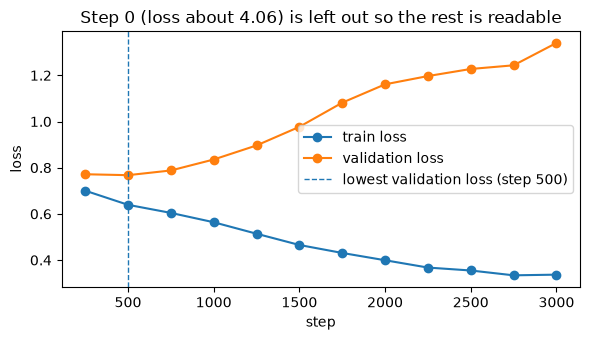

In [7]:
import matplotlib.pyplot as plt

steps = [r[0] for r in log]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(steps[1:], [r[1] for r in log[1:]], marker="o", label="train loss")
ax.plot(steps[1:], [r[2] for r in log[1:]], marker="o", label="validation loss")
ax.axvline(best[1], linestyle="--", linewidth=1, label=f"lowest validation loss (step {best[1]})")
ax.set_xlabel("step")
ax.set_ylabel("loss")
ax.set_title("Step 0 (loss about 4.06) is left out so the rest is readable")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Sample at three temperatures, from two checkpoints

The kept weights (step 500) and the last weights (step 3000) each write 200 names at temperature 0.5, 1.0 and
1.6. The cell prints the first ten names of each set and the counts.

**Look for:** with the step-500 weights, 0.5 repeats the same few street types and copies 43 names; 1.0 is
varied and spelled correctly (27 copies); 1.6 has misspellings such as "Limedalk Way" and only 122 of 200 are
well formed. The step-3000 weights copy far more: 191 of 200 at temperature 0.5.

In [8]:
model.eval()
sets = {}
for tag, state in (("best", best[2]), ("final", final_state)):
    model.load_state_dict(state)
    for temp in (0.5, 1.0, 1.6):
        names, st = sample_stats(temp, n=200, seed=1)
        sets[(tag, temp)] = (names, st)
        step = best[1] if tag == "best" else STEPS
        print(f"step {step} weights, temperature {temp}:  copies {st['copies']}, unique {st['unique']}, "
              f"well formed {st['well_formed']}, usable {st['usable']} (of {st['n']})")
        print("   first ten:", names[:10])

step 500 weights, temperature 0.5:  copies 43, unique 161, well formed 200, usable 129 (of 200)
   first ten: ['Birchside Terrace', 'Marketgate Walk', 'Brookton Walk', 'Westford Grove', 'Brookdale Walk', 'Chapelford Grove', 'Brookford Street', 'Silvergate Walk', 'Abbeylands Walk', 'Abbeylands Grove']


step 500 weights, temperature 1.0:  copies 27, unique 190, well formed 194, usable 158 (of 200)
   first ten: ['Birchton Lane', 'Birchside Lane', 'Southford Drive', 'Ferndale Place', 'Swanton Close', 'Millton Way', 'Hawthornside Place', 'Beechbury Terrace', 'Stonewood Close', 'Stationside Street']


step 500 weights, temperature 1.6:  copies 12, unique 198, well formed 122, usable 108 (of 200)
   first ten: ['Birbury Rogatlands Walk', 'Limedalk Way', 'Hwan Terrace', 'Millford Place', 'Southwood Grove', 'Fern Greve', 'Greencroft GIve', 'Capelside Lane', 'Southford Creclaceld Grove', 'Garden Walk']


step 3000 weights, temperature 0.5:  copies 191, unique 102, well formed 198, usable 7 (of 200)
   first ten: ['Birchton Grove', 'Abbeygate Lane', 'Bridgegate Walk', 'Birch Walk', 'Grangedale Walk', 'Fernwood Close', 'Chapelton Lane', 'Yorkton Grove', 'Stationfield Gardens', 'Limedale Street']


step 3000 weights, temperature 1.0:  copies 158, unique 158, well formed 194, usable 35 (of 200)
   first ten: ['Birchton Terrace', 'ChapelsLondale Close', 'Orchard Way', 'Millton Place', 'Schardwood Grove', 'Fern Walk', 'Swandale Way', 'Ivylands Road', 'Limesioldale Gardens', 'Stationside Drive']


step 3000 weights, temperature 1.6:  copies 85, unique 189, well formed 175, usable 90 (of 200)
   first ten: ['Birchton Terrace', 'ChapelsLondale Way', 'Mewton Close', 'Brookford Place', 'Southwood Grove', 'Fern Walk', 'Swandale Row', 'Ivylands Road', 'geford Road', 'Brookdale Gardens']


## 9. Generate, then filter

The team keeps a name only if it is **new** (not in the training list), **well formed**, and **not a repeat**
of one already kept. This cell applies that filter to the four settings from the lesson's last question.

**Look for:** step-500 weights at temperature 1.0 give the most usable names (158 of 200). Even that setting
copied 27 names from the list, so the filter is not optional.

In [9]:
def keep_usable(names):
    kept = []
    for nm in names:
        if nm not in train_set and well_formed(nm) and nm not in kept:
            kept.append(nm)
    return kept

for tag, temp in (("final", 0.5), ("best", 1.0), ("best", 1.6), ("final", 1.0)):
    names, st = sets[(tag, temp)]
    step = best[1] if tag == "best" else STEPS
    print(f"step {step} weights, temperature {temp}:  copies {st['copies']:3d}   usable {len(keep_usable(names)):3d}")

print("\nsome usable names (step 500, temperature 1.0):", keep_usable(sets[("best", 1.0)][0])[:8])

step 3000 weights, temperature 0.5:  copies 191   usable   7
step 500 weights, temperature 1.0:  copies  27   usable 158
step 500 weights, temperature 1.6:  copies  12   usable 108
step 3000 weights, temperature 1.0:  copies 158   usable  35

some usable names (step 500, temperature 1.0): ['Birchside Lane', 'Southford Drive', 'Ferndale Place', 'Swanton Close', 'Millton Way', 'Hawthornside Place', 'Beechbury Terrace', 'Stonewood Close']


## 10. The scores after "Ashford "

Back to the kept weights. The model reads `"\nAshford "` and gives a score (a logit) to each of the 48
characters. We round them to 3 decimals, as the lesson does.

**Look for:** the ten highest scores are the first letters of street types (G for Grove, C for Close or
Crescent, R, W, P, T, A, D, S, L), all between about 5.3 and 6.9. Everything else is far lower: B is next
at about 1.6.

In [10]:
model.load_state_dict(best[2])
with torch.no_grad():
    lg = model(torch.tensor([encode("\nAshford ")]))[0, -1]
order = torch.argsort(lg, descending=True).tolist()
scores = {chars[i]: round(lg[i].item(), 3) for i in order}
for ch, s in list(scores.items())[:12]:
    print(f"{ch!r:5} {s:7.3f}")

'G'     6.869
'C'     6.574
'R'     6.229
'W'     6.127
'P'     6.011
'T'     5.466
'A'     5.439
'D'     5.398
'S'     5.355
'L'     5.336
'B'     1.611
'H'     1.275


## 11. Temperature sampling from scratch

`sample_next` is the lesson's plain-Python sampler: divide the scores by the temperature, softmax, then walk
the characters (highest score first) adding up probabilities until the total passes a random number `draw`.
The same `draw` (from `random.Random(0)`) is used at both temperatures.

**Look for:** `draw` = 0.844. At temperature 0.5 the top letter G gets 0.399 and the sampler returns **P**. At
1.0 G gets only 0.230, the top letters share less of the line, and the same draw returns **D**.

In [11]:
def sample_next(scores, temperature, draw):
    scaled = {ch: s / temperature for ch, s in scores.items()}
    top = max(scaled.values())
    weights = {ch: math.exp(s - top) for ch, s in scaled.items()}
    total = sum(weights.values())
    probs = {ch: w / total for ch, w in weights.items()}
    running = 0.0
    for ch, p in probs.items():
        running += p
        if draw < running:
            return ch
    return ch

def probs_at(scores, temperature):
    top = max(scores.values()) / temperature
    w = {ch: math.exp(s / temperature - top) for ch, s in scores.items()}
    total = sum(w.values())
    return {ch: x / total for ch, x in w.items()}

draw = random.Random(0).random()
print(f"draw: {draw:.3f}")
for T in (0.5, 1.0):
    p = probs_at(scores, T)
    running, walk = 0.0, []
    for ch in list(scores)[:8]:
        running += p[ch]
        walk.append(f"{ch} {running:.3f}")
    print(f"\ntemperature {T}: p(G) = {p['G']:.3f}")
    print("   running totals:", ", ".join(walk))
    print("   sample_next returns:", repr(sample_next(scores, T, draw)))

draw: 0.844

temperature 0.5: p(G) = 0.399
   running totals: G 0.399, C 0.621, R 0.732, W 0.822, P 0.894, T 0.918, A 0.941, D 0.962
   sample_next returns: 'P'

temperature 1.0: p(G) = 0.230
   running totals: G 0.230, C 0.401, R 0.522, W 0.631, P 0.728, T 0.785, A 0.840, D 0.892
   sample_next returns: 'D'


## Now change it

Three small experiments. Each cell has one line marked `# <- change`. Edit it and run that cell again.

### Experiment 1: your own temperature

The kept weights write 200 names at the temperature in the marked line. Try 0.2, then 2.0.

**What should change:** at 0.2 the copies go up and the unique names go down (even more than at 0.5), because
dividing by a small number makes the top letters win almost every time, and the likeliest paths are names from
the list. At 2.0 copies fall but many names are broken, so "well formed" drops.

In [12]:
TEMP = 1.0  # <- change: try 0.2, then 2.0
model.load_state_dict(best[2])
names, st = sample_stats(TEMP, n=200, seed=1)
print(f"temperature {TEMP}: copies {st['copies']}, unique {st['unique']}, "
      f"well formed {st['well_formed']}, usable {st['usable']} (of {st['n']})")
print("first ten:", names[:10])

temperature 1.0: copies 27, unique 190, well formed 194, usable 158 (of 200)
first ten: ['Birchton Lane', 'Birchside Lane', 'Southford Drive', 'Ferndale Place', 'Swanton Close', 'Millton Way', 'Hawthornside Place', 'Beechbury Terrace', 'Stonewood Close', 'Stationside Street']


### Experiment 2: a different random draw

The sampler from step 11 with a draw you choose. It starts at 0.3. Try 0.995.

**What should change:** with 0.3, temperature 0.5 returns G (G alone covers the first 0.399 of the line) but
temperature 1.0 returns C (G covers only 0.230, so the walk needs C too). With 0.995, temperature 0.5 still
returns L, one of the ten street-type letters, because at 0.5 those ten cover almost the whole line (0.99997).
At 1.0 they cover only about 0.992, so the same draw lands on O, a letter that starts no street type: this is how
high temperatures make misspellings.

In [13]:
MY_DRAW = 0.3  # <- change: try 0.995
for T in (0.5, 1.0):
    print(f"temperature {T}, draw {MY_DRAW}: sample_next returns {sample_next(scores, T, MY_DRAW)!r}")

temperature 0.5, draw 0.3: sample_next returns 'G'
temperature 1.0, draw 0.3: sample_next returns 'C'


### Experiment 3: a start loss that signals a bug

A fresh, untrained model, but with the `head` weights multiplied by the number in the marked line. Try 30.

**What should change:** with 1 the start loss is near ln 48 = 3.87. With 30 the head gives large random scores,
so the model is confidently wrong before it has learned anything, and the start loss is far above ln 48.
This is the check from the lesson's interview question: compare the first loss with ln(vocabulary size).

In [14]:
HEAD_SCALE = 1  # <- change: try 30
torch.manual_seed(42)
fresh = TinyGPT()
with torch.no_grad():
    fresh.head.weight.mul_(HEAD_SCALE)
    xb, yb = get_batch(train_text)
    loss0 = F.cross_entropy(fresh(xb).view(-1, V), yb.view(-1)).item()
print(f"head scale {HEAD_SCALE}: start loss {loss0:.2f}   (ln V = {math.log(V):.2f})")

head scale 1: start loss 4.04   (ln V = 3.87)


## What you should see

- The loss printed at step 0 is near ln 48 ≈ 3.87 (our run: 4.06).
- Train loss keeps going down after that (ours: 0.639 at step 500, 0.337 at step 3000).
- Validation loss reaches its lowest early (ours: 0.768 at step 500) and then rises (1.340 at step 3000).
- Copies of list names in the log climb after that (ours: 10 of 100 at step 500, 22 at step 750, 81 at step 3000).
- At temperature 1.6 some names are misspelled; at 0.5 the same few street types repeat.

If Colab has a newer PyTorch than the lesson's run (2.15), your numbers may differ a little. The story stays
the same: validation loss turns, copies climb, and the kept checkpoint at temperature 1.0 gives the most usable
names.